# Rolling 12-month IPCA forecast errors

This notebook evaluates one **12-month-ahead Focus forecast per month**, rather than one forecast for each calendar year. For month M, it takes the last available Focus observation in M with `Suavizada = 'N'` and `baseCalculo = 0`. At month-end, the first IPCA month not yet published is M, so the forecast covers M through M+11. The realized outcome is `100 × (IBGE index at M+11 / IBGE index at M−1 − 1)`. This is **compounded 12-month inflation**, not the arithmetic average of 12 monthly rates.

The BCB explains the non-smoothed 12-month forecast in its [Focus methodology, questions 14–15](https://www.bcb.gov.br/content/controleinflacao/Documents/Expectativas_mercado/FAQ13-Expectativas-de-Mercado.pdf). The realized index comes from [IBGE SIDRA table 1737, variable 2266](https://apisidra.ibge.gov.br/values/t/1737/n1/all/v/2266/p/200110-202512), saved locally on November 2, 2026. The database snapshot is identified by `dados/atual.json`.

## 1. Load the local Focus snapshot and IBGE index

Run the notebook from the repository root or from `projects/`. The IBGE CSV is versioned; the Focus SQLite snapshot must be available locally.

In [1]:
suppressPackageStartupMessages({
  library(DBI)
  library(RSQLite)
  library(jsonlite)
})

project_root <- if (file.exists('dados/atual.json')) {
  '.'
} else if (file.exists('../dados/atual.json')) {
  '..'
} else {
  stop('Cannot find dados/atual.json; run from the repository root or projects/.')
}
snapshot <- fromJSON(file.path(project_root, 'dados/atual.json'))
ibge <- read.csv(file.path(project_root, 'projects/data/ibge_ipca_monthly_index_200110_202512.csv'),
                 colClasses = c('character', 'numeric'))
expected_index_months <- format(seq(as.Date('2001-10-01'), as.Date('2025-12-01'), by = 'month'), '%Y%m')
stopifnot(identical(ibge$month, expected_index_months),
          all(is.finite(ibge$ipca_index)), all(ibge$ipca_index > 0))
cat('Focus snapshot:', snapshot$coleta, '\n')
cat('IBGE index months:', nrow(ibge), '\n')

Focus snapshot: 20261029T204913Z 


IBGE index months: 291 


## 2. Select the last non-smoothed forecast in each month

The selected Focus date must be no more than seven days before month-end. This avoids silently using a stale forecast. The analysis starts with November 2001, the first month with available observations in this Focus series, and ends with January 2025, whose 12-month outcome ends in December 2025.

In [2]:
con <- dbConnect(SQLite(), file.path(project_root, snapshot$banco))
focus <- tryCatch(dbGetQuery(con, '
  WITH ranked AS (
    SELECT substr(Data, 1, 7) AS forecast_month,
           Data AS forecast_date,
           Mediana AS forecast_ipca_12m_pct,
           DesvioPadrao AS disagreement_pp,
           numeroRespondentes AS respondents,
           ROW_NUMBER() OVER (PARTITION BY substr(Data, 1, 7) ORDER BY Data DESC) AS rn
    FROM ExpectativasMercadoInflacao12Meses
    WHERE Indicador = ? AND Suavizada = ? AND baseCalculo = ?
      AND Data >= ? AND Data < ?
  )
  SELECT forecast_month, forecast_date, forecast_ipca_12m_pct,
         disagreement_pp, respondents,
         CAST(julianday(date(forecast_month || "-01", "+1 month", "-1 day"))
              - julianday(forecast_date) AS INTEGER) AS days_before_month_end,
         strftime("%Y%m", date(forecast_month || "-01", "-1 month")) AS index_before_window,
         strftime("%Y%m", date(forecast_month || "-01", "+11 months")) AS outcome_end_month
  FROM ranked WHERE rn = 1 ORDER BY forecast_month
', params = list('IPCA', 'N', 0L, '2001-11-01', '2025-02-01')),
finally = dbDisconnect(con))
expected_forecast_months <- format(seq(as.Date('2001-11-01'), as.Date('2025-01-01'), by = 'month'), '%Y-%m')
stopifnot(identical(focus$forecast_month, expected_forecast_months),
          !anyNA(focus$forecast_ipca_12m_pct), !anyNA(focus$disagreement_pp),
          all(focus$days_before_month_end >= 0 & focus$days_before_month_end <= 7))
cat('Monthly forecasts:', nrow(focus), '\n')
head(focus, 3)

Monthly forecasts: 279 


,forecast_month,forecast_date,forecast_ipca_12m_pct,disagreement_pp,respondents,days_before_month_end,index_before_window,outcome_end_month
,<chr>,<chr>,<dbl>,<dbl>,<int>,<int>,<chr>,<chr>
1,2001-11,2001-11-30,5.67,0.59,NA,0,200110,200210
2,2001-12,2001-12-31,4.77,0.57,NA,0,200111,200211
3,2002-01,2002-01-31,4.83,0.37,NA,0,200112,200212


## 3. Match each forecast to realized inflation

The IBGE index immediately **before** the forecast month is the denominator; the index 11 months **after** the forecast month is the numerator. The signed error is `Focus forecast − realized inflation` in percentage points. A positive error means overprediction.

In [3]:
start_row <- match(focus$index_before_window, ibge$month)
end_row <- match(focus$outcome_end_month, ibge$month)
stopifnot(!anyNA(start_row), !anyNA(end_row))
focus$realized_ipca_12m_pct <- 100 * (ibge$ipca_index[end_row] / ibge$ipca_index[start_row] - 1)
focus$error_pp <- focus$forecast_ipca_12m_pct - focus$realized_ipca_12m_pct
focus$absolute_error_pp <- abs(focus$error_pp)
stopifnot(round(focus$realized_ipca_12m_pct[1], 2) == 8.45,
          round(tail(focus$realized_ipca_12m_pct, 1), 2) == 4.26)

selected <- focus[c('forecast_month', 'forecast_date', 'outcome_end_month',
                    'forecast_ipca_12m_pct', 'realized_ipca_12m_pct',
                    'error_pp', 'absolute_error_pp', 'disagreement_pp')]
print(head(selected, 6), row.names = FALSE, digits = 4)
print(tail(selected, 6), row.names = FALSE, digits = 4)

 forecast_month forecast_date outcome_end_month forecast_ipca_12m_pct
        2001-11    2001-11-30            200210                  5.67
        2001-12    2001-12-31            200211                  4.77
        2002-01    2002-01-31            200212                  4.83
        2002-02    2002-02-28            200301                  4.72
        2002-03    2002-03-28            200302                  4.92
        2002-04    2002-04-30            200303                  4.92
 realized_ipca_12m_pct error_pp absolute_error_pp disagreement_pp
                 8.445   -2.775             2.775            0.59
                10.933   -6.163             6.163            0.57
                12.530   -7.700             7.700            0.37
                14.467   -9.747             9.747            0.33
                15.847  -10.927            10.927            0.38
                16.573  -11.653            11.653            0.40


 forecast_month forecast_date outcome_end_month forecast_ipca_12m_pct
        2024-08    2024-08-30            202507                 3.772
        2024-09    2024-09-30            202508                 4.135
        2024-10    2024-10-31            202509                 4.167
        2024-11    2024-11-29            202510                 4.385
        2024-12    2024-12-31            202511                 4.972
        2025-01    2025-01-31            202512                 5.580
 realized_ipca_12m_pct error_pp absolute_error_pp disagreement_pp
                 5.225  -1.4533            1.4533          0.3678
                 5.130  -0.9956            0.9956          0.4070
                 5.172  -1.0055            1.0055          0.4402
                 4.681  -0.2960            0.2960          0.5139
                 4.462   0.5099            0.5099          0.5279
                 4.264   1.3157            1.3157          0.6135


## 4. Summarize the errors

Consecutive outcomes overlap by 11 months, so the 279 errors are **not independent observations**. Descriptive statistics below should not be treated as confidence intervals.

In [4]:
summary_rolling <- data.frame(
  months = nrow(focus),
  mean_signed_error_pp = mean(focus$error_pp),
  mean_absolute_error_pp = mean(focus$absolute_error_pp),
  median_absolute_error_pp = median(focus$absolute_error_pp),
  rmse_pp = sqrt(mean(focus$error_pp^2))
)
print(summary_rolling, row.names = FALSE, digits = 4)


 months mean_signed_error_pp mean_absolute_error_pp median_absolute_error_pp
    279               -1.036                  1.809                    1.127
 rmse_pp
   2.879


## 5. Forecast, realized IPCA, and error

The x-axis is the **forecast month**. The realized line shows inflation in the subsequent 12-month window, which was not known at the forecast date. The lower panel is forecast minus realized IPCA in percentage points.

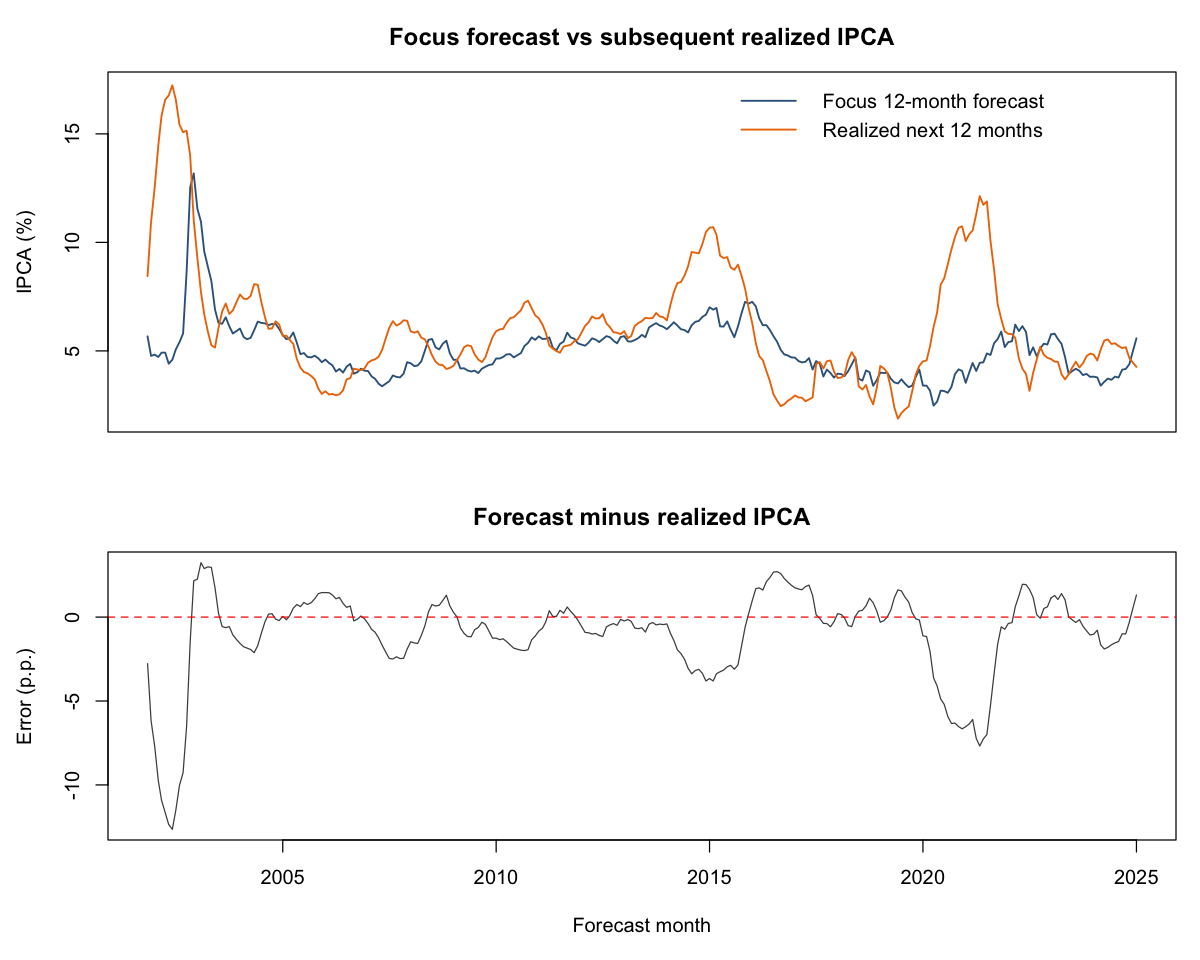

In [5]:
plot_month <- as.Date(paste0(focus$forecast_month, '-01'))
options(repr.plot.width = 10, repr.plot.height = 8)
old_par <- par(no.readonly = TRUE)
par(bg = 'white', mfrow = c(2, 1), mar = c(2, 4.5, 3, 1))

plot(plot_month, focus$forecast_ipca_12m_pct, type = 'l',
     col = 'steelblue4', lwd = 1.5, xaxt = 'n', xlab = '',
     ylim = range(c(focus$forecast_ipca_12m_pct, focus$realized_ipca_12m_pct)),
     ylab = 'IPCA (%)', main = 'Focus forecast vs subsequent realized IPCA')
lines(plot_month, focus$realized_ipca_12m_pct, col = 'darkorange2', lwd = 1.5)
legend('topright', c('Focus 12-month forecast', 'Realized next 12 months'),
       col = c('steelblue4', 'darkorange2'), lty = 1, lwd = 1.5, bty = 'n')

par(mar = c(5, 4.5, 3, 1))
plot(plot_month, focus$error_pp, type = 'l', col = 'grey30',
     xlab = 'Forecast month', ylab = 'Error (p.p.)',
     main = 'Forecast minus realized IPCA')
abline(h = 0, col = 'red', lty = 2)
par(old_par)

## 6. Distribution of signed errors

Negative values indicate underprediction; positive values indicate overprediction. The histogram shows the observed distribution but does not account for overlap between adjacent forecast windows.

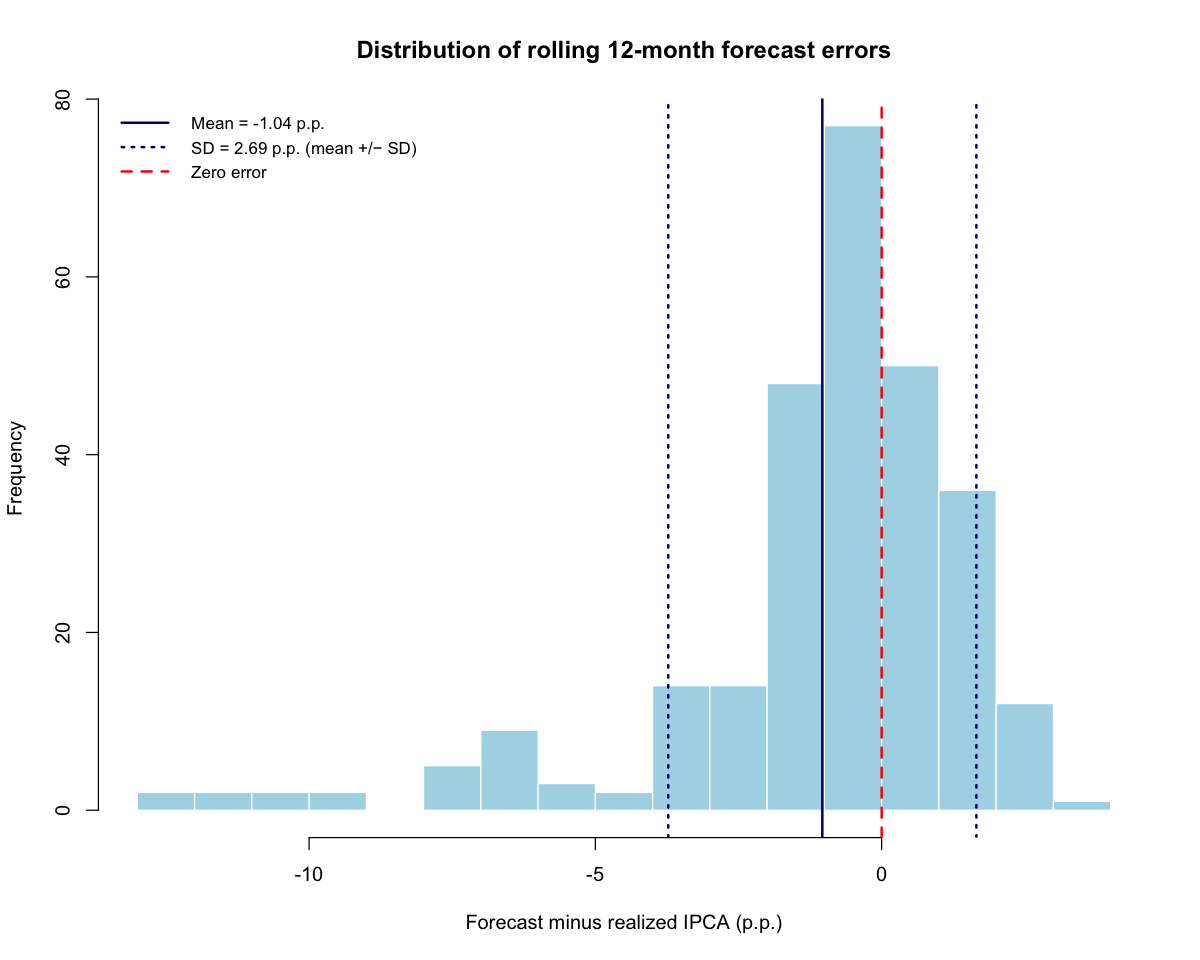

In [6]:
mean_error <- mean(focus$error_pp)
sd_error <- sd(focus$error_pp)

par(bg = 'white')
hist(focus$error_pp, breaks = 20, col = 'lightblue', border = 'white',
     main = 'Distribution of rolling 12-month forecast errors',
     xlab = 'Forecast minus realized IPCA (p.p.)')
abline(v = 0, col = 'red', lty = 2, lwd = 2)
abline(v = mean_error, col = 'navy', lwd = 2)
abline(v = mean_error + c(-sd_error, sd_error), col = 'navy', lty = 3, lwd = 2)
legend('topleft',
       legend = c(sprintf('Mean = %.2f p.p.', mean_error),
                  sprintf('SD = %.2f p.p. (mean +/− SD)', sd_error),
                  'Zero error'),
       col = c('navy', 'navy', 'red'), lty = c(1, 3, 2), lwd = 2,
       bty = 'n', cex = 0.85)
